In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import pandas as pd
import numpy as np
import gzip
import csv
import urllib.request

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE42nnn/GSE42568/matrix/GSE42568_series_matrix.txt.gz"

urllib.request.urlretrieve(url, "GSE42568_series_matrix.txt.gz")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [9]:
import pandas as pd

file = "GSE42568_series_matrix.txt.gz"

df = pd.read_csv(
    file,
    sep="\t",
    comment="!",
    compression="gzip"
)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (54675, 122)
      ID_REF  GSM1045191  GSM1045192  GSM1045193  GSM1045194  GSM1045195  \
0  1007_s_at    5.640239    3.557696    3.132007    6.865108    4.955184   
1    1053_at    5.074866    4.984593    5.109481    5.473609    5.348400   
2     117_at    4.191770    4.269061    4.131843    3.616546    4.296657   
3     121_at    3.574706    4.065623    3.574706    3.574706    3.799293   
4  1255_g_at    2.312812    2.409371    2.312812    2.312812    2.349630   

   GSM1045196  GSM1045197  GSM1045198  GSM1045199  ...  GSM1045302  \
0    5.573674    4.714100    5.234298    5.050853  ...    6.953623   
1    5.572707    5.675239    5.792026    6.185706  ...    5.453186   
2    4.184048    4.000772    4.984939    4.958126  ...    4.209247   
3    3.803312    3.643243    4.053245    3.574706  ...    3.574706   
4    2.312812    2.312812    2.312812    2.312812  ...    2.312812   

   GSM1045303  GSM1045304  GSM1045305  GSM1045306  GSM1045307  GSM1045308  \
0    7.007825    

In [10]:
# Check missing values
print("Missing values:")
print(df.isnull().sum().sum())

# Remove duplicate probe IDs
df = df.drop_duplicates(subset="ID_REF")

# Replace infinite values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing expression values
df = df.dropna()

print("Cleaned dataset shape:", df.shape)
print("Cleaning completed!")

Missing values:
0
Cleaned dataset shape: (54675, 122)
Cleaning completed!


In [13]:
import gzip
import csv

# Extract sample titles from GEO metadata
with gzip.open(file, "rt") as f:
    lines = f.readlines()

title_line = next(
    line for line in lines
    if line.startswith("!Sample_title")
)

titles = next(csv.reader([title_line], delimiter="\t"))[1:]

# Prepare expression matrix
expression = df.set_index("ID_REF").apply(
    pd.to_numeric, errors="coerce"
)

# Convert probes into rows and samples into columns
sample_expression = expression.T

metadata = pd.DataFrame({
    "sample_id": sample_expression.index,
    "title": titles
})

metadata["condition"] = metadata["title"].apply(
    lambda x: "Normal" if "normal" in x.lower()
    else "Cancer" if "cancer" in x.lower()
    else "Unknown"
)

print(metadata["condition"].value_counts())

# Sample-level statistics
sample_expression["condition"] = metadata[
    "condition"
].values

print(sample_expression.groupby("condition").mean().mean(axis=1))

condition
Cancer    104
Normal     17
Name: count, dtype: int64
condition
Cancer    4.131387
Normal    4.110001
dtype: float64


In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare expression matrix
expression = df.set_index("ID_REF").apply(
    pd.to_numeric, errors="coerce"
)

sample_matrix = expression.T

# Calculate statistics for each sample
sample_stats = pd.DataFrame({
    "sample_id": sample_matrix.index,
    "mean_expression": sample_matrix.mean(axis=1).values,
    "median_expression": sample_matrix.median(axis=1).values,
    "std_expression": sample_matrix.std(axis=1).values
})

# Add cancer/normal labels
sample_stats = sample_stats.merge(
    metadata[["sample_id", "condition"]],
    on="sample_id",
    how="left"
)

print("Sample statistics:")
display(sample_stats.head())

print("\nSample groups:")
print(sample_stats["condition"].value_counts())

Sample statistics:


,sample_id,mean_expression,median_expression,std_expression,condition
0,GSM1045191,4.157925,2.790573,2.432000,Normal
1,GSM1045192,3.990590,3.110262,2.123931,Normal
2,GSM1045193,3.997157,3.178932,2.093154,Normal
3,GSM1045194,3.999663,3.105461,2.127519,Normal
4,GSM1045195,4.147220,2.768904,2.444450,Normal



Sample groups:
condition
Cancer    104
Normal     17
Name: count, dtype: int64


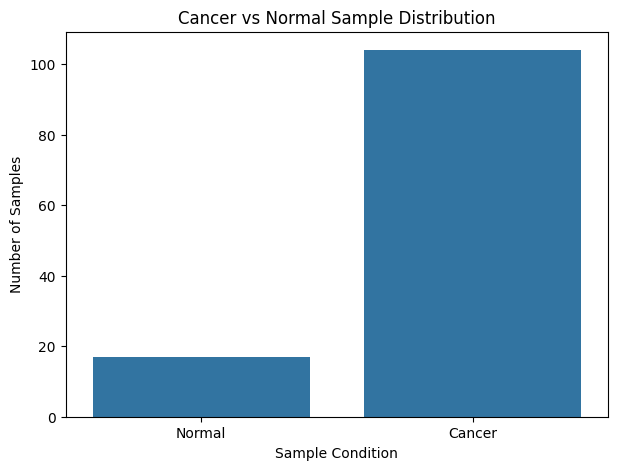

In [15]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=sample_stats,
    x="condition"
)

plt.title("Cancer vs Normal Sample Distribution")
plt.xlabel("Sample Condition")
plt.ylabel("Number of Samples")

plt.savefig("chart1_sample_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

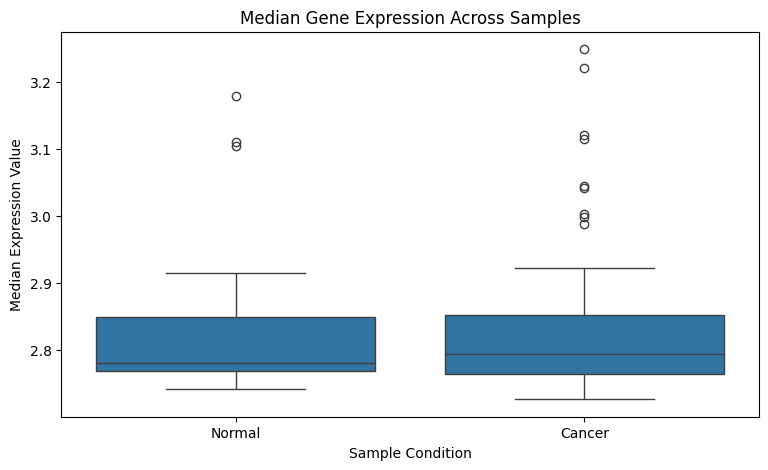

In [16]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sample_stats,
    x="condition",
    y="median_expression"
)

plt.title("Median Gene Expression Across Samples")
plt.xlabel("Sample Condition")
plt.ylabel("Median Expression Value")

plt.savefig("chart2_expression_boxplot.png",
            dpi=300, bbox_inches="tight")
plt.show()

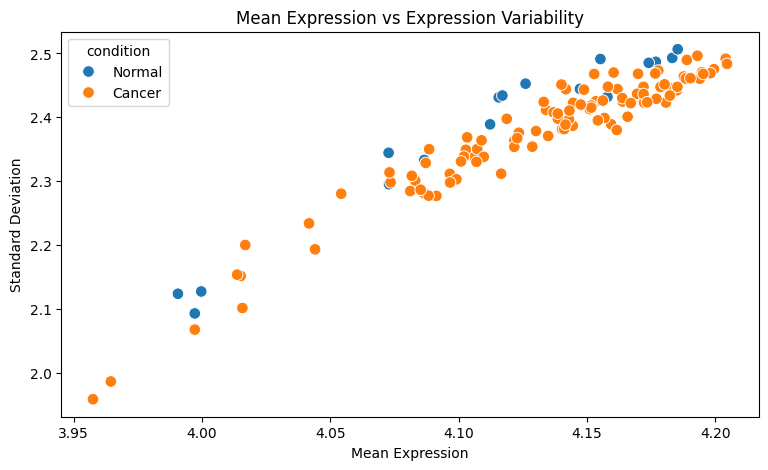

In [17]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=sample_stats,
    x="mean_expression",
    y="std_expression",
    hue="condition",
    s=70
)

plt.title("Mean Expression vs Expression Variability")
plt.xlabel("Mean Expression")
plt.ylabel("Standard Deviation")

plt.savefig("chart3_expression_scatter.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [18]:

group_results = sample_stats.groupby("condition").agg({
    "mean_expression": ["mean", "std"],
    "median_expression": ["mean", "std"],
    "std_expression": ["mean", "std"]
})

display(group_results)

group_results.to_csv("task3_group_results.csv")

print("Group comparison completed!")

mean_expression           median_expression            \
                     mean       std              mean       std   
condition                                                         
Cancer           4.131387  0.052600          2.825681  0.097132   
Normal           4.110001  0.065262          2.853742  0.139995   

          std_expression            
                    mean       std  
condition                           
Cancer          2.373890  0.101318  
Normal          2.374363  0.137641

Group comparison completed!


In [ ]:
from google.colab import files
import zipfile

task3_files = [
    "chart1_sample_distribution.png",
    "chart2_expression_boxplot.png",
    "chart3_expression_scatter.png",
    "task3_group_results.csv"
]

with zipfile.ZipFile("SWYNEX_Task3_Results.zip", "w") as z:
    for filename in task3_files:
        z.write(filename)

files.download("SWYNEX_Task3_Results.zip")